In [ ]:
!pip install -q kagglehub tensorflow scikit-learn pandas matplotlib seaborn

In [ ]:
import kagglehub
import os

path = kagglehub.dataset_download(
    "zarajamshaid/language-identification-datasst"
)

print("Dataset downloaded successfully!")
print("Dataset path:", path)

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

Using Colab cache for faster access to the 'language-identification-datasst' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/language-identification-datasst
/kaggle/input/language-identification-datasst/dataset.csv


In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
csv_files = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True
)

if not csv_files:
    raise FileNotFoundError(
        "CSV file not found. Check the downloaded dataset."
    )

print("Available CSV files:")
for i, file in enumerate(csv_files):
    print(i, file)

# First CSV file
df = pd.read_csv(csv_files[0])

print("\nDataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Available CSV files:
0 /kaggle/input/language-identification-datasst/dataset.csv

Dataset shape: (22000, 2)

First five rows:


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch



Column names:
['Text', 'language']


In [ ]:
print("Original columns:", df.columns.tolist())

# Identify text and language columns
text_candidates = [
    "text", "sentence", "text_sample", "content"
]

label_candidates = [
    "language", "lang", "label", "target"
]

def find_column(candidates, columns):
    column_map = {str(c).strip().lower(): c for c in columns}

    for candidate in candidates:
        if candidate in column_map:
            return column_map[candidate]

    return None

text_col = find_column(text_candidates, df.columns)
label_col = find_column(label_candidates, df.columns)

# If automatic detection fails, set actual column names here.
# Example: text_col = "Text"
#          label_col = "language"

if text_col is None or label_col is None:
    raise ValueError(
        "Could not identify columns. Set text_col and label_col "
        "using the column names printed above."
    )

print("Text column:", text_col)
print("Language column:", label_col)

# Keep only required columns
df = df[[text_col, label_col]].copy()
df.columns = ["text", "language"]

# Handle missing values
df = df.dropna(subset=["text", "language"])

# Convert to strings and remove extra whitespace
df["text"] = df["text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

# Remove empty text and labels
df = df[
    (df["text"] != "") &
    (df["language"] != "")
]

# Remove duplicate samples
df = df.drop_duplicates(subset=["text", "language"])

print("\nCleaned dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nLanguage distribution:")
print(df["language"].value_counts())

Original columns: ['Text', 'language']
Text column: Text
Language column: language

Cleaned dataset shape: (21858, 2)

Missing values:
text        0
language    0
dtype: int64

Language distribution:
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


In [ ]:
MAX_SAMPLES_PER_LANGUAGE = 1000

# Sample dynamically: take up to MAX_SAMPLES_PER_LANGUAGE depending on what is available
df = (
    df.groupby("language", group_keys=False)
      .apply(lambda x: x.sample(n=min(len(x), MAX_SAMPLES_PER_LANGUAGE), random_state=42, replace=False))
      .reset_index(drop=True)
)

# Keep languages with enough samples for train/test splitting
counts = df["language"].value_counts()
valid_languages = counts[counts >= 10].index

df = df[df["language"].isin(valid_languages)].reset_index(drop=True)

print("Subset shape:", df.shape)
print("Number of languages:", df["language"].nunique())
print("\nSamples per language:")
print(df["language"].value_counts())

Subset shape: (21858, 2)
Number of languages: 22

Samples per language:
language
Chinese       1000
English       1000
Romanian      1000
Persian       1000
Japanese      1000
Korean        1000
Thai          1000
Turkish       1000
Urdu          1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


/tmp/ipykernel_4472/672991331.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(len(x), MAX_SAMPLES_PER_LANGUAGE), random_state=42, replace=False))


In [ ]:
X = df["text"].values
y = df["language"].values

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of language classes:", len(label_encoder.classes_))
print("\nLanguages:", label_encoder.classes_)

Training samples: 17486
Testing samples: 4372
Number of language classes: 22

Languages: ['Arabic' 'Chinese' 'Dutch' 'English' 'Estonian' 'French' 'Hindi'
 'Indonesian' 'Japanese' 'Korean' 'Latin' 'Persian' 'Portugese' 'Pushto'
 'Romanian' 'Russian' 'Spanish' 'Swedish' 'Tamil' 'Thai' 'Turkish' 'Urdu']


In [ ]:
MAX_WORDS = 20000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

# Convert text to numerical sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Pad sequences to equal length
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)

print("Vocabulary size:", vocab_size)
print("Training data shape:", X_train_pad.shape)
print("Testing data shape:", X_test_pad.shape)

print("\nOriginal text:")
print(X_train[0])

print("\nNumerical sequence:")
print(X_train_seq[0][:20])

print("\nPadded sequence:")
print(X_train_pad[0][:20])

Vocabulary size: 20000
Training data shape: (17486, 100)
Testing data shape: (4372, 100)

Original text:
일리단과 결별한 이후 나이트 엘프들에게 사악한 마법을 쓰지 말라는 법을 발표하였으나 여왕인 아즈샤라가 이것을 어김으로써 아즈샤라와 그녀의 신하들은 모두 바다 속으로 가라앉아 나가 족으로 승화됨으로써 아즈샤라와도 결별한다 그리고 칼림도어 깊은 숲에서 오랜 세월을 은둔하며 지내다가 때마침 오크 호드의 전쟁노래 부족이 칼림도어에 침공하였다는 소식을 듣고 선전포고를 한다 처음에는 세나리우스의 대부대가 이끄는 은빛날개단이 우세하였으나 결국 그롬마쉬 "그롬" 헬스크림이 사악한 만노로스의 피를 받아들이고 세나리우스에게 일격을 가함으로써 세나리우스는 전사한다

Numerical sequence:
[1, 1, 548, 1954, 1, 6235, 5470, 1, 1, 1, 1, 1, 1, 15229, 1, 1, 10382, 1, 2275, 13192]

Padded sequence:
[    1     1   548  1954     1  6235  5470     1     1     1     1     1
     1 15229     1     1 10382     1  2275 13192]


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dropout, Dense, Input

# Define vocabulary size and number of languages
vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)
num_classes = len(label_encoder.classes_)

# Build LSTM model
model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(num_classes, activation="softmax")
])

# Compile model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 100, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 22)             │           726 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,315,830 (5.02 MB)

 Trainable params: 1,315,830 (5.02 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/5
246/246 ━━━━━━━━━━━━━━━━━━━━ 43s 124ms/step - accuracy: 0.3014 - loss: 2.2151 - val_accuracy: 0.6438 - val_loss: 1.2771
Epoch 2/5
246/246 ━━━━━━━━━━━━━━━━━━━━ 38s 114ms/step - accuracy: 0.6204 - loss: 1.1447 - val_accuracy: 0.8188 - val_loss: 0.6908
Epoch 3/5
246/246 ━━━━━━━━━━━━━━━━━━━━ 42s 117ms/step - accuracy: 0.7647 - loss: 0.7155 - val_accuracy: 0.8691 - val_loss: 0.4091
Epoch 4/5
246/246 ━━━━━━━━━━━━━━━━━━━━ 28s 114ms/step - accuracy: 0.8835 - loss: 0.3949 - val_accuracy: 0.9057 - val_loss: 0.3173
Epoch 5/5
246/246 ━━━━━━━━━━━━━━━━━━━━ 28s 114ms/step - accuracy: 0.9114 - loss: 0.2893 - val_accuracy: 0.9160 - val_loss: 0.2495


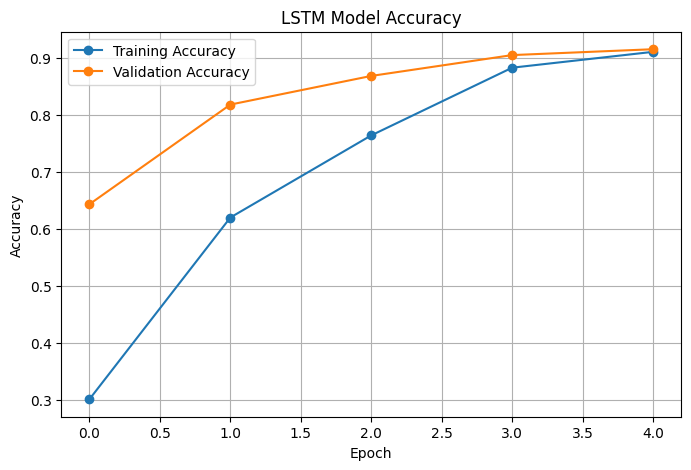

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
y_prob = model.predict(X_test_pad, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("MODEL EVALUATION RESULTS")
print("-" * 35)
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

MODEL EVALUATION RESULTS
-----------------------------------
Accuracy  : 0.9161
Precision : 0.9130
Recall    : 0.9163
F1-score  : 0.9060


In [ ]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Arabic       0.99      0.99      0.99       200
     Chinese       0.28      0.03      0.05       200
       Dutch       0.99      0.98      0.98       199
     English       0.89      0.97      0.93       200
    Estonian       0.97      0.91      0.94       200
      French       0.97      0.92      0.95       198
       Hindi       0.99      0.99      0.99       198
  Indonesian       0.98      0.98      0.98       195
    Japanese       0.45      0.90      0.60       200
      Korean       1.00      0.97      0.99       200
       Latin       0.94      0.95      0.95       191
     Persian       0.98      0.98      0.98       200
   Portugese       0.99      0.97      0.98       199
      Pushto       1.00      0.92      0.96       199
    Romanian       0.98      0.97      0.98       200
     Russian       0.99      0.98      0.99       200
     Spanish       0.99      0.96      0.98       199
     Swedish       0.99    

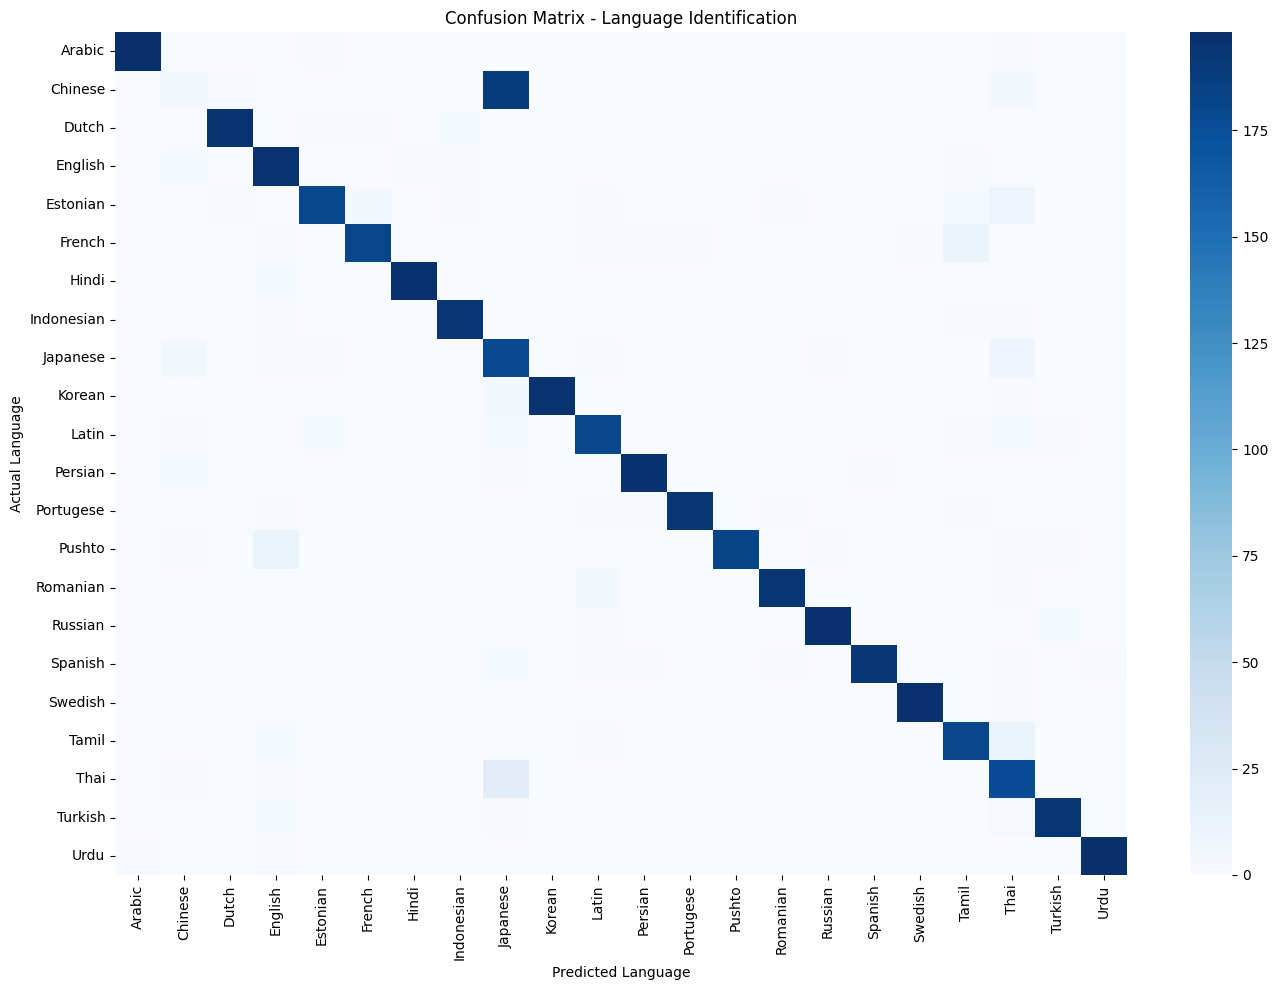

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=(num_classes <= 15),
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Language Identification")
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
unseen_texts = [
    "Hello, how are you today?",
    "Hola, ¿cómo estás? Me alegro de verte.",
    "Bonjour, comment allez-vous aujourd'hui?",
    "Guten Morgen, wie geht es Ihnen?",
    "Ciao, come stai? È bello vederti."
]

# Convert unseen text using the SAME tokenizer
unseen_seq = tokenizer.texts_to_sequences(unseen_texts)

unseen_pad = pad_sequences(
    unseen_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

# Predict probabilities
predictions = model.predict(unseen_pad, verbose=0)

predicted_indices = np.argmax(predictions, axis=1)
confidence_scores = np.max(predictions, axis=1)

print("UNSEEN TEXT LANGUAGE PREDICTIONS")
print("=" * 60)

for i, text in enumerate(unseen_texts):
    predicted_language = label_encoder.inverse_transform(
        [predicted_indices[i]]
    )[0]

    confidence = confidence_scores[i] * 100

    print(f"\nSample {i + 1}: {text}")
    print(f"Predicted Language: {predicted_language}")
    print(f"Confidence: {confidence:.2f}%")

UNSEEN TEXT LANGUAGE PREDICTIONS

Sample 1: Hello, how are you today?
Predicted Language: Japanese
Confidence: 34.03%

Sample 2: Hola, ¿cómo estás? Me alegro de verte.
Predicted Language: Japanese
Confidence: 45.19%

Sample 3: Bonjour, comment allez-vous aujourd'hui?
Predicted Language: Japanese
Confidence: 39.93%

Sample 4: Guten Morgen, wie geht es Ihnen?
Predicted Language: Chinese
Confidence: 42.43%

Sample 5: Ciao, come stai? È bello vederti.
Predicted Language: Japanese
Confidence: 38.21%


In [ ]:
user_text = input("Enter a sentence: ")

sequence = tokenizer.texts_to_sequences([user_text])

padded = pad_sequences(
    sequence,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

prediction = model.predict(padded, verbose=0)[0]

index = np.argmax(prediction)
language = label_encoder.inverse_transform([index])[0]

print("\nPredicted Language:", language)
print(f"Confidence: {prediction[index] * 100:.2f}%")

Enter a sentence: klement gottwaldi surnukeha palsameeriti ning paigutati mausoleumi surnukeha oli aga liiga hilja ja oskamatult palsameeritud ning hakkas ilmutama lagunemise tundemÃ¤rke  aastal viidi ta surnukeha mausoleumist 

Predicted Language: Estonian
Confidence: 99.48%
